In [1]:
import pandas as pd
from mplsoccer.pitch import Pitch
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure
import numpy

figure(figsize=(8, 6), dpi=80)

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

In [2]:
def get_event_locations(df, event=None, place=None, result=None, team=None):
    if event:
        df_event = df.loc[df['type_name'] == event]
    else:
        df_event = df
    if team:
        df_event = df_event.loc[df['team_id'] == team]
    if result:
        df_event = df_event.loc[df['result_name'] == result]
    location = [[x, y] for x,y in zip(df_event[f'{place}_x'].values, df_event[f'{place}_y'].values)]
    df_event['location'] = location
    location_xy = df_event.location.apply(pd.Series)
    location_xy.columns = ['x', 'y']
    return location_xy

def draw_heatmap(df, title, x_areas=12, y_areas=8, event=None, place=None, result=None, team=None, pitch_type='uefa'):
    location_xy = get_event_locations(df, event=event, place=place, result=result, team=team)
    pitch = Pitch(line_zorder=2, line_color='black', pitch_type=pitch_type)
    fig, ax = pitch.grid(figheight=4, grid_height=0.9, title_height=0.06, axis=False,
                        endnote_height=0.04, title_space=0, endnote_space=0)
    bin_statistic = pitch.bin_statistic(location_xy.x, location_xy.y, statistic='count', bins=(x_areas, y_areas), normalize=False)
    bin_statistic["statistic"] = bin_statistic["statistic"]
    pcm  = pitch.heatmap(bin_statistic, cmap='Reds', edgecolor='grey', ax=ax['pitch'])
    ax_cbar = fig.add_axes((1, 0.093, 0.03, 0.786))
    cbar = plt.colorbar(pcm, cax=ax_cbar)
    fig.suptitle(title, fontsize = 16)
    plt.show()

In [3]:
wsl = pd.read_hdf('data-opta-woman-all/spadl-opta.h5', "games")
wsl_game_ids = wsl['game_id'].values
wsl_game_ids

array([1077833, 1077836, 1077837, 1077835, 1077834, 1077890, 1077884,
       1077853, 1077847, 1077927, 1077933, 1077932, 1077926, 1077852,
       1077885, 1077891, 1077893, 1077844, 1077850, 1077930, 1077924,
       1077925, 1077931, 1077851, 1077845, 1077879, 1077892, 1077886,
       1077882, 1077896, 1077841, 1077855, 1077869, 1077909, 1077908,
       1077934, 1077868, 1077854, 1077840, 1077897, 1077883, 1077895,
       1077881, 1077856, 1077842, 1077923, 1077843, 1077857, 1077880,
       1077894, 1077899, 1077872, 1077866, 1077906, 1077912, 1077907,
       1077867, 1077873, 1077859, 1077865, 1077871, 1077911, 1077905,
       1077904, 1077910, 1077870, 1077864, 1077858, 1077860, 1077874,
       1077848, 1077914, 1077900, 1077928, 1077915, 1077849, 1077875,
       1077861, 1077877, 1077863, 1077903, 1077902, 1077862, 1077876,
       1077889, 1077839, 1077838, 2138467, 2138473, 2138498, 2138499,
       2138472, 2138466, 2138470, 2138464, 2138458, 2138459, 2138465,
       2138471, 2138

In [4]:
wsl_matches = []

for id in wsl_game_ids:
    wsl_matches.append(pd.read_hdf('data-opta-woman-all/features.h5', f"game_{id}"))

wsl_matches = pd.concat(wsl_matches, ignore_index=True)
wsl_matches

,type_id_a0,type_id_a1,type_id_a2,type_pass_a0,type_cross_a0,type_throw_in_a0,type_freekick_crossed_a0,type_freekick_short_a0,type_corner_crossed_a0,type_corner_short_a0,...,time_seconds_a0,time_seconds_overall_a0,period_id_a1,time_seconds_a1,time_seconds_overall_a1,period_id_a2,time_seconds_a2,time_seconds_overall_a2,time_delta_1,time_delta_2
0,0,0,0,True,False,False,False,False,False,False,...,1.0,1.0,1,1.0,1.0,1,1.0,1.0,0.0,0.0
1,21,0,0,False,False,False,False,False,False,False,...,2.5,2.5,1,1.0,1.0,1,1.0,1.0,1.5,1.5
2,0,21,0,True,False,False,False,False,False,False,...,4.0,4.0,1,2.5,2.5,1,1.0,1.0,1.5,3.0
3,0,0,21,True,False,False,False,False,False,False,...,5.0,5.0,1,4.0,4.0,1,2.5,2.5,1.0,2.5
4,0,0,0,True,False,False,False,False,False,False,...,8.0,8.0,1,5.0,5.0,1,4.0,4.0,3.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
492680,0,0,0,True,False,False,False,False,False,False,...,3054.0,5754.0,2,3050.0,5750.0,2,3046.0,5746.0,4.0,8.0
492681,0,0,0,True,False,False,False,False,False,False,...,3059.0,5759.0,2,3054.0,5754.0,2,3050.0,5750.0,5.0,9.0
492682,21,0,0,False,False,False,False,False,False,False,...,3063.0,5763.0,2,3059.0,5759.0,2,3054.0,5754.0,4.0,9.0
492683,1,21,0,False,True,False,False,False,False,False,...,3067.0,5767.0,2,3063.0,5763.0,2,3059.0,5759.0,4.0,8.0


In [17]:
wsl_matches_pass = wsl_matches[wsl_matches['type_pass_a0'] == True]  # type: ignore
wsl_matches_pass = wsl_matches_pass[wsl_matches['type_pass_a1'] == True]  # type: ignore
wsl_matches_pass = wsl_matches_pass[wsl_matches['type_pass_a2'] == True]  # type: ignore

wsl_matches_pass.rename(columns = {'start_x_a0':'start_x', 'start_y_a0':'start_y', 'end_x_a0':'end_x', 'end_y_a0':'end_y'}, inplace = True)  # type: ignore
locations = [(x, y) for x, y in zip(wsl_matches_pass['start_x'], wsl_matches_pass['start_y'])]
wsl_matches_pass['location'] = locations
wsl_matches_pass = wsl_matches_pass[wsl_matches_pass['location'] != (52.5, 34.0)]  # type: ignore


wsl_matches_pass_success = wsl_matches_pass[wsl_matches_pass['result_success_a0'] == True]
wsl_matches_pass_fail = wsl_matches_pass[wsl_matches_pass['result_success_a0'] == False]

In [18]:
for col in wsl_matches_pass_success.columns:
    if type(wsl_matches_pass_success[col].values[0]) == numpy.bool_:
        unique_values = wsl_matches_pass_success[col].unique()
        if len(unique_values) > 1:
            print(col)
            print(wsl_matches_pass_success[col].unique())


bodypart_foot_a0
[ True False]
bodypart_head_a0
[False  True]
bodypart_head/other_a0
[False  True]
bodypart_foot_a1
[ True False]
bodypart_head_a1
[False  True]
bodypart_head/other_a1
[False  True]
bodypart_foot_a2
[ True False]
bodypart_head_a2
[False  True]
bodypart_head/other_a2
[False  True]
result_fail_a1
[False  True]
result_success_a1
[ True False]
result_offside_a1
[False  True]
result_fail_a2
[False  True]
result_success_a2
[ True False]
result_offside_a2
[False  True]
team_1
[ True False]
team_2
[ True False]


C:\Users\mattyl\AppData\Local\Temp\ipykernel_23612\1767323113.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_event['location'] = location


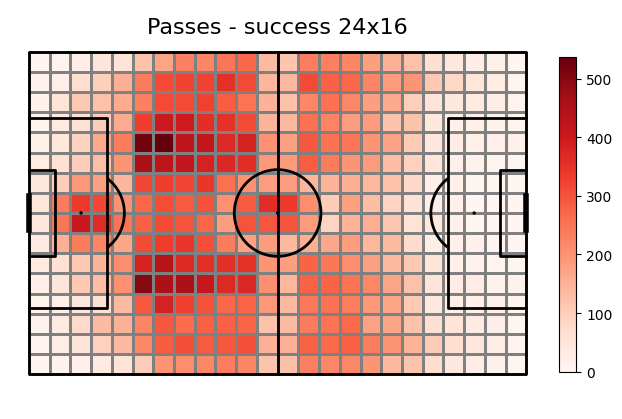

C:\Users\mattyl\AppData\Local\Temp\ipykernel_23612\1767323113.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_event['location'] = location


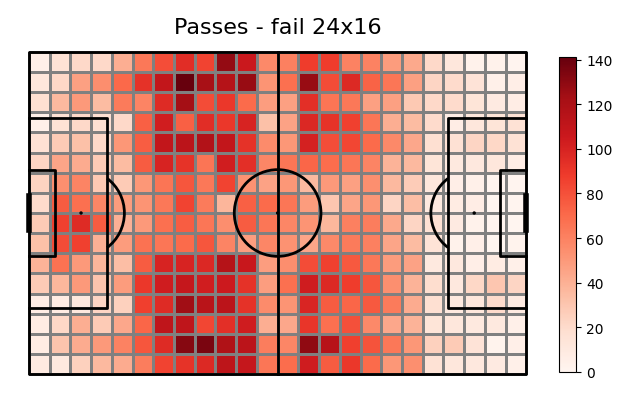

In [19]:
draw_heatmap(df=wsl_matches_pass_success, place='start', title='Passes - success 24x16', x_areas=24, y_areas=16)
draw_heatmap(df=wsl_matches_pass_fail, place='start', title='Passes - fail 24x16', x_areas=24, y_areas=16)

In [21]:
for col in wsl_matches.columns:
    if type(wsl_matches[col].values[0]) == numpy.bool_:
        print(col)


type_pass_a0
type_cross_a0
type_throw_in_a0
type_freekick_crossed_a0
type_freekick_short_a0
type_corner_crossed_a0
type_corner_short_a0
type_take_on_a0
type_foul_a0
type_tackle_a0
type_interception_a0
type_shot_a0
type_shot_penalty_a0
type_shot_freekick_a0
type_keeper_save_a0
type_keeper_claim_a0
type_keeper_punch_a0
type_keeper_pick_up_a0
type_clearance_a0
type_bad_touch_a0
type_non_action_a0
type_dribble_a0
type_goalkick_a0
type_pass_a1
type_cross_a1
type_throw_in_a1
type_freekick_crossed_a1
type_freekick_short_a1
type_corner_crossed_a1
type_corner_short_a1
type_take_on_a1
type_foul_a1
type_tackle_a1
type_interception_a1
type_shot_a1
type_shot_penalty_a1
type_shot_freekick_a1
type_keeper_save_a1
type_keeper_claim_a1
type_keeper_punch_a1
type_keeper_pick_up_a1
type_clearance_a1
type_bad_touch_a1
type_non_action_a1
type_dribble_a1
type_goalkick_a1
type_pass_a2
type_cross_a2
type_throw_in_a2
type_freekick_crossed_a2
type_freekick_short_a2
type_corner_crossed_a2
type_corner_short_a2
type

In [33]:
risk_areas = wsl_matches[(wsl_matches['type_take_on_a0'] == True) | (wsl_matches['type_take_on_a1'] == True) | (wsl_matches['type_take_on_a2'] == True) | 
(wsl_matches['type_tackle_a0'] == True) | (wsl_matches['type_tackle_a1'] == True) | (wsl_matches['type_tackle_a2'] == True) |
    (wsl_matches['type_interception_a0'] == True) | (wsl_matches['type_interception_a1'] == True) | (wsl_matches['type_interception_a2'] == True)]
risk_areas.rename(columns = {'start_x_a0':'start_x', 'start_y_a0':'start_y', 'end_x_a0':'end_x', 'end_y_a0':'end_y'}, inplace = True)  # type: ignore
risk_areas

C:\Users\mattyl\AppData\Local\Temp\ipykernel_23612\3226809767.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  risk_areas.rename(columns = {'start_x_a0':'start_x', 'start_y_a0':'start_y', 'end_x_a0':'end_x', 'end_y_a0':'end_y'}, inplace = True)  # type: ignore


,type_id_a0,type_id_a1,type_id_a2,type_pass_a0,type_cross_a0,type_throw_in_a0,type_freekick_crossed_a0,type_freekick_short_a0,type_corner_crossed_a0,type_corner_short_a0,...,time_seconds_a0,time_seconds_overall_a0,period_id_a1,time_seconds_a1,time_seconds_overall_a1,period_id_a2,time_seconds_a2,time_seconds_overall_a2,time_delta_1,time_delta_2
16,9,0,21,False,False,False,False,False,False,False,...,37.0,37.0,1,31.0,31.0,1,27.5,27.5,6.0,9.5
17,0,9,0,True,False,False,False,False,False,False,...,41.0,41.0,1,37.0,37.0,1,31.0,31.0,4.0,10.0
18,21,0,9,False,False,False,False,False,False,False,...,42.5,42.5,1,41.0,41.0,1,37.0,37.0,1.5,5.5
37,9,18,1,False,False,False,False,False,False,False,...,128.0,128.0,1,127.0,127.0,1,123.0,123.0,1.0,5.0
38,21,9,18,False,False,False,False,False,False,False,...,131.0,131.0,1,128.0,128.0,1,127.0,127.0,3.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
492646,21,9,10,False,False,False,False,False,False,False,...,2840.0,5540.0,2,2838.0,5538.0,2,2838.0,5538.0,2.0,2.0
492647,0,21,9,True,False,False,False,False,False,False,...,2842.0,5542.0,2,2840.0,5540.0,2,2838.0,5538.0,2.0,4.0
492650,10,0,21,False,False,False,False,False,False,False,...,2845.0,5545.0,2,2845.0,5545.0,2,2843.5,5543.5,0.0,1.5
492651,21,10,0,False,False,False,False,False,False,False,...,2849.5,5549.5,2,2845.0,5545.0,2,2845.0,5545.0,4.5,4.5


C:\Users\mattyl\AppData\Local\Temp\ipykernel_23612\1767323113.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_event['location'] = location


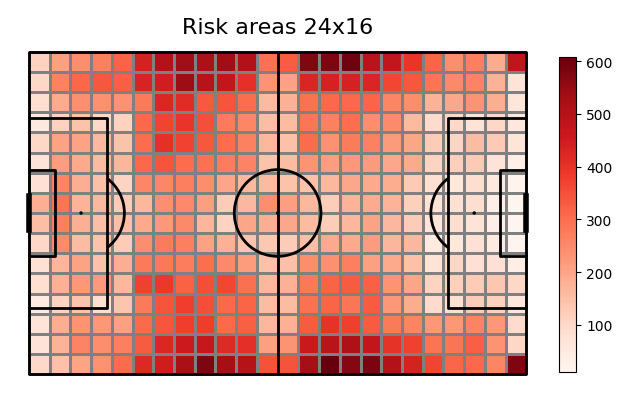

In [34]:
draw_heatmap(df=risk_areas, place='start', title='Risk areas 24x16', x_areas=24, y_areas=16)